**AICE Associate <font color=red>딥러닝 모델링 연습문항</font>**

### <span style="color:darkgreen">**통신사 고객 데이터를 활용한 해지(termination) 예측 — 딥러닝**</span>
---

- 도메인 : 통신
- 목  표 : 11번 문항과 같은 데이터로, tensorflow 딥러닝 모델을 만들어 해지 여부를 예측합니다.

#### **<span style="color:red">[유의사항]</span>**
- 문항에 변수명이 제시된 경우 반드시 해당 변수명을 사용하세요.
- "안내된 내용 외 별도의 파라미터를 입력하지 마세요" 라는 가이드가 있으면 지시된 옵션만 사용하세요.
- 딥러닝 결과(정확도 등)는 실행 환경에 따라 소수점 아래가 조금씩 다를 수 있습니다.

**[ 데이터 컬럼 설명 (데이터 파일명: cust_data1.csv) ]** — 11번과 동일
- class, sex, age, service, stop, npay, avg_bill, A_bill, B_bill, termination(Y/N) ← 예측 대상

---

### **1. tensorflow를 별칭(alias) tf로 불러오세요.**
---

In [1]:
# [1번 정답]
import tensorflow as tf

> **다음 문항을 풀기 전에 <span style="color:red">아래 코드를 실행하세요.</span>**

In [2]:
import platform
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.font_manager as fm
import warnings
warnings.filterwarnings('ignore')

# OS에 따라서 한글 폰트 로드
os_name = platform.system()

if os_name == 'Linux':
    font_names = [f.name for f in fm.fontManager.ttflist]
    for cand in ['NanumGothicCoding', 'NanumGothic', 'Noto Sans CJK KR', 'Noto Sans CJK JP']:
        if cand in font_names:
            plt.rc('font', family=cand)
            break
    print("(리눅스) 한글폰트 로드 완료")
elif os_name == 'Windows':
    font_path = 'C:\\Windows\\Fonts\\malgun.ttf'
    font = fm.FontProperties(fname=font_path).get_name()
    mpl.rc('font', family=font)
    print("(윈도우) 한글폰트 로드 완료")
elif os_name == 'Darwin':
    plt.rc('font', family='AppleGothic')
    print("(맥) 한글폰트 로드 완료")
else:
    print(f"알 수 없는 OS입니다: {os_name}")

# 마이너스 기호 깨짐 방지
mpl.rcParams['axes.unicode_minus'] = False

(리눅스) 한글폰트 로드 완료


<br>

### **2. 아래 전처리 코드를 실행하세요. (11번에서 연습한 내용입니다)**
---
- 이상치 제거(avg_bill IQR, age > 100) → 결측치 처리 → termination 0/1 변환 → 원-핫 인코딩 → df_preset

In [3]:
# [2번] 아래 코드를 그대로 실행하세요.
df = pd.read_csv('./cust_data1.csv')

q1, q3 = df['avg_bill'].quantile(0.25), df['avg_bill'].quantile(0.75)
upper_fence = q3 + 1.5 * (q3 - q1)
df_temp = df.drop(df[df['avg_bill'] > upper_fence].index, axis=0)
df_temp = df_temp.drop(df_temp[df_temp['age'] > 100].index, axis=0).reset_index(drop=True)

df_na = df_temp.dropna(subset=['class']).copy()
df_na['age'] = df_na['age'].fillna(df_na['age'].median())
for col in ['avg_bill', 'A_bill']:
    df_na[col] = df_na[col].fillna(df_na[col].mean())

df_na['termination'] = df_na['termination'].map({'Y': 1, 'N': 0})
df_preset = pd.get_dummies(data=df_na, columns=['class', 'sex', 'stop', 'npay'], dtype=int)
print(df_preset.shape)
df_preset.head(3)

(9646, 20)


,age,service,avg_bill,A_bill,B_bill,termination,class_A,class_B,class_C,class_D,class_E,class_F,class_G,class_H,sex_F,sex_M,stop_N,stop_Y,npay_N,npay_Y
0,61.0,2,7190.9881,3479.1102,2878.7129,0,0,1,0,0,0,0,0,0,1,0,1,0,1,0
1,55.0,1,25045.0340,23940.8983,648.1402,0,0,0,0,0,1,0,0,0,0,1,1,0,0,1
2,29.0,4,24942.9410,20637.5226,4894.4189,0,0,0,0,1,0,0,0,0,0,1,1,0,0,1


<br>

### **3. 훈련/검증 데이터를 분리하고 MinMaxScaler로 스케일링하세요.**
---
- termination을 y, 나머지를 X로 할당하세요.
- 훈련:검증 = 80:20, 난수 시드 42, 해지 비율 유지(stratify)
- MinMaxScaler를 mm 변수에 지정하고, 훈련데이터는 학습+변환, 검증데이터는 변환만 하세요. (변수명은 그대로 X_train, X_valid)
- 코드의 빈칸 '< blank3-1 >', '< blank3-2 >', '< blank3-3 >'을 채우고, 빈칸 내용을 '답안3_1', '답안3_2', '답안3_3'에 저장하세요.
---

In [4]:
# [3번 정답]
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

X = df_preset.drop('termination', axis=1)
y = df_preset['termination']
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

mm = MinMaxScaler()
X_train = mm.fit_transform(X_train)
X_valid = mm.transform(X_valid)
print(X_train.shape, X_valid.shape)

답안3_1 = 'stratify'
답안3_2 = 'fit_transform'
답안3_3 = 'transform'

(7716, 19) (1930, 19)


<br>

> **딥러닝 모델을 구현하기 위해 <span style="color:red">아래 함수를 불러오는 코드를 실행하세요.</span>**

In [5]:
import tensorflow as tf
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Dense, Activation, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.utils import to_categorical

tf.random.set_seed(1)

<br>

### **4. 해지 여부를 예측하는 딥러닝 모델을 만들고 학습하세요. (출력 1개 이진분류)**
---
- 아래 토폴로지와 동일한 모델을 Sequential로 구현하고 model 변수에 저장하세요.

| 순서 | 층 | 설정 |
|---|---|---|
| 1 | Dense | 64 유닛, relu, 입력 피처 수 = X_train의 컬럼 수 |
| 2 | Dropout | 0.2 |
| 3 | Dense | 32 유닛, relu |
| 4 | Dense | 16 유닛, relu |
| 5 | Dense (출력) | 1 유닛, sigmoid |

- EarlyStopping: val_loss가 **5 epoch** 동안 개선되지 않으면 중단 → estop 변수
- ModelCheckpoint: val_loss 기준 가장 좋은 모델만 'best_model.keras'로 저장 → mc 변수
- optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'] 로 컴파일
- epochs=50, batch_size=64, 검증데이터 지정, 콜백 [estop, mc] 로 학습하고 history 변수에 저장
- 코드의 빈칸 '< blank4-1 >' ~ '< blank4-4 >'를 채우고, 빈칸 내용을 '답안4_1' ~ '답안4_4'에 저장하세요.
---

In [6]:
# [4번 정답]
model = Sequential()
model.add(Dense(64, activation='relu', input_dim=X_train.shape[1]))
model.add(Dropout(0.2))
model.add(Dense(32, activation='relu'))
model.add(Dense(16, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

estop = EarlyStopping(monitor='val_loss', patience=5)
mc = ModelCheckpoint('best_model.keras', monitor='val_loss', save_best_only=True)

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
history = model.fit(X_train, y_train, epochs=50, batch_size=64,
                    validation_data=(X_valid, y_valid), callbacks=[estop, mc], verbose=2)

답안4_1 = 'input_dim'
답안4_2 = 'Dropout'
답안4_3 = 'sigmoid'
답안4_4 = 'patience'

Epoch 1/50


121/121 - 1s - 12ms/step - accuracy: 0.7871 - loss: 0.4604 - val_accuracy: 0.8927 - val_loss: 0.3060


Epoch 2/50


121/121 - 0s - 3ms/step - accuracy: 0.8638 - loss: 0.3396 - val_accuracy: 0.8964 - val_loss: 0.2827


Epoch 3/50


...

121/121 - 0s - 3ms/step - accuracy: 0.8805 - loss: 0.2925 - val_accuracy: 0.9031 - val_loss: 0.2717


Epoch 41/50


121/121 - 0s - 3ms/step - accuracy: 0.8828 - loss: 0.2917 - val_accuracy: 0.9047 - val_loss: 0.2710


Epoch 42/50


121/121 - 0s - 3ms/step - accuracy: 0.8839 - loss: 0.2922 - val_accuracy: 0.9036 - val_loss: 0.2713


<br>

### **5. 학습 Loss와 검증 Loss의 변화를 시각화하세요.**
---
- 1개의 그래프에 학습 loss와 검증 loss를 모두 표시하세요.
- 범례: 'loss', 'val_loss' / 제목: 'Model Loss' / X축: 'Epoch' / Y축: 'Loss'
---

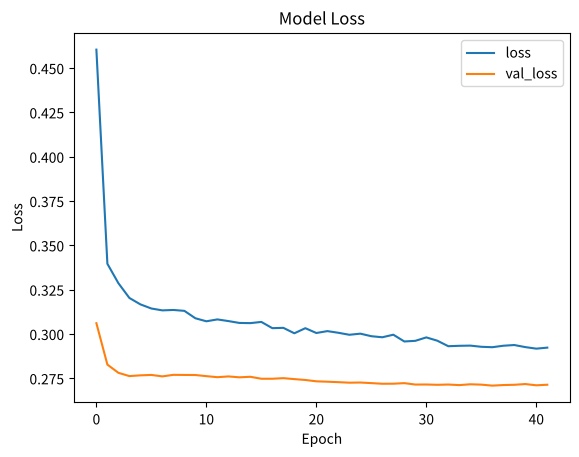

In [7]:
# [5번 정답]
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['loss', 'val_loss'])
plt.show()

<br>

### **6. 학습된 모델로 검증데이터를 예측하고 성능을 평가하세요.**
---
- model.predict로 검증데이터의 해지 확률을 구하고, 0.5보다 크면 1, 아니면 0으로 변환해 y_pred 변수에 저장하세요.
- accuracy_score와 recall_score를 출력하세요.
- **accuracy를 소수점 둘째 자리까지 반올림**한 값을 '답안6' 변수에 저장하세요. (예: 답안6 = 0.12)
- 아래 코드의 오류를 정정하세요.
---

In [8]:
# [6번 정답]
from sklearn.metrics import accuracy_score, recall_score

proba = model.predict(X_valid, verbose=0)
y_pred = (proba > 0.5).astype(int).ravel()

print('accuracy:', accuracy_score(y_valid, y_pred))
print('recall  :', recall_score(y_valid, y_pred))

답안6 = 0.9     # 딥러닝은 실행할 때마다 값이 약간 다를 수 있습니다 (본인 출력값을 기준으로)

accuracy: 0.9036269430051813
recall  : 0.637883008356546


<br>

### **7. 이번에는 출력이 2개인 모델을 만들려고 합니다. (샘플 문항 형태)**
---
- 타깃이 문자열('Y'/'N')인 상황을 연습하기 위해, 아래 셀에서 만든 문자열 라벨 y_train_str, y_valid_str을 사용합니다.
- y_train_str, y_valid_str을 LabelEncoder로 정수로 바꾼 뒤 to_categorical로 원-핫 형태로 바꾸세요.
- 모델(model2): Dense(128, relu, 입력) → Dropout(0.3) → Dense(64, relu) → Dense(32, relu) → Dense(2, sigmoid)
- EarlyStopping(val_loss, patience=14) → estop
- optimizer='adam', loss='binary_crossentropy', metrics=['accuracy']
- batch_size=128, epochs=30, 학습정보는 history2에 저장
- 아래 코드의 **오류를 모두 정정**하세요.
---

In [9]:
# [7번] 문자열 라벨 준비 (그대로 실행)
y_train_str = np.where(y_train == 1, 'Y', 'N')
y_valid_str = np.where(y_valid == 1, 'Y', 'N')
print(y_train_str[:5])

['N' 'Y' 'N' 'N' 'N']


In [10]:
# [7번 정답]
# ① Sequential에는 층을 '리스트'로 전달  ② 출력층은 Dense(2, ...)  ③ patients -> patience
# ④ metrics는 리스트 ['accuracy']  ⑤ 검증 라벨은 transform  ⑥ validation_data에 y_valid2 사용
from sklearn.preprocessing import LabelEncoder

model2 = Sequential([
    Dense(128, activation='relu', input_dim=X_train.shape[1]),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(2, activation='sigmoid')
])

estop = EarlyStopping(monitor='val_loss', patience=14)
model2.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

le = LabelEncoder()
y_train2 = le.fit_transform(y_train_str)
y_valid2 = le.transform(y_valid_str)

y_train2 = to_categorical(y_train2)
y_valid2 = to_categorical(y_valid2)

history2 = model2.fit(X_train, y_train2, epochs=30, batch_size=128,
                      validation_data=(X_valid, y_valid2), callbacks=[estop], verbose=2)

Epoch 1/30


61/61 - 1s - 22ms/step - accuracy: 0.8149 - loss: 0.4522 - val_accuracy: 0.8275 - val_loss: 0.3399


Epoch 2/30


61/61 - 0s - 4ms/step - accuracy: 0.8560 - loss: 0.3538 - val_accuracy: 0.8943 - val_loss: 0.2949


Epoch 3/30


...

61/61 - 0s - 4ms/step - accuracy: 0.8817 - loss: 0.2975 - val_accuracy: 0.9031 - val_loss: 0.2711


Epoch 29/30


61/61 - 0s - 4ms/step - accuracy: 0.8813 - loss: 0.2991 - val_accuracy: 0.9031 - val_loss: 0.2710


Epoch 30/30


61/61 - 0s - 4ms/step - accuracy: 0.8830 - loss: 0.2957 - val_accuracy: 0.9010 - val_loss: 0.2712


<br>

### **8. model2의 학습 Accuracy와 검증 Accuracy 변화를 시각화하세요.**
---
- 범례: 'acc', 'val_acc' / 제목: 'Model Accuracy' / X축: 'Epoch' / Y축: 'Accuracy'
- 코드의 빈칸 '< blank8-1 >', '< blank8-2 >'를 채우고, 빈칸 내용을 '답안8_1', '답안8_2'에 저장하세요.
---

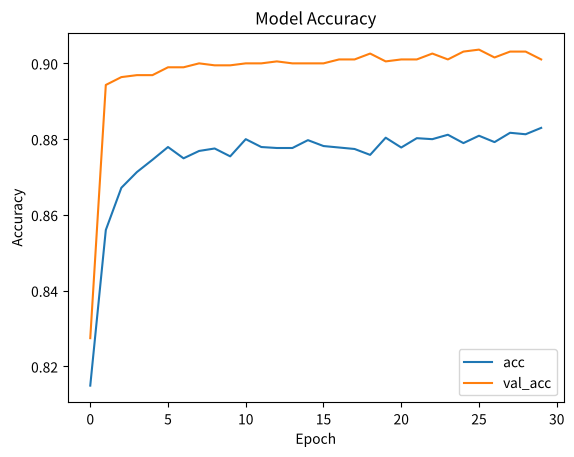

In [11]:
# [8번 정답]
plt.plot(history2.history["accuracy"])
plt.plot(history2.history["val_accuracy"])
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend(['acc', 'val_acc'])
plt.show()

답안8_1 = 'history2.history'
답안8_2 = 'legend'

<br>

### **9. (심화) 저장된 최적 모델(best_model.keras)을 불러와 검증데이터로 평가하세요.**
---
- load_model로 불러와 best_model 변수에 저장하세요.
- evaluate 결과(loss, accuracy)를 출력하세요.
---

In [12]:
# [9번 정답]
best_model = load_model('best_model.keras')
loss, acc = best_model.evaluate(X_valid, y_valid, verbose=0)
print(f"loss={loss:.4f}, accuracy={acc:.4f}")

loss=0.2708, accuracy=0.9016


<br>

### **모든 문항이 완료되었습니다. 수고하셨습니다.**